> **Reproducible version.** This is a copy of `forex_exchange_analysis_new.ipynb` (left unchanged) updated to run on current library versions: `statsmodels.tsa.arima.model.ARIMA` replaces the removed `arima_model` API, the CSV path points to the file in this repository, `np.NAN` → `np.nan`, the currency is set by a variable instead of a prompt, and a persistence baseline has been added to the evaluation. The analysis itself is unchanged.


# AIMS AND OBJECTIVES OF THIS SOFTWARE

1. Producing the Analysis of this forex exchange rate dataset, covering the historical aspects over the period of time, 
    in short doing Timeseries Analysis
    
2. Data Cleansing and Transformation of Forex Exchange Dataset in order to transform it in format or structure required during 
    Timeseries Analysis and Machine Learning
  
3. Visualization of Forex Exchange Dataset based on Timeseries Analysis done on it.

4. Applying ARIMA MODEL, a Machine Learning algorithm, used to perform forecasting or predicting future value 

# IMPORTING REQUIRED PYTHON LIBRARIES & LOADING DATASET

We need all below libraries, that we're importing, in our Anaconda distribution in order for this notebook work correctly and show us desired results.

In [1]:
# Used for Data Analysis
import pandas as pd
# Used For Visualization
import matplotlib as mpl 
from matplotlib import pyplot as plt
# Used for Scientific Computation
import numpy as np

# Python Machine Learning Modules and Packages

# Used to implement ARIMA Model
# statsmodels >= 0.13 removed statsmodels.tsa.arima_model; the maintained class lives here
from statsmodels.tsa.arima.model import ARIMA
# Used to calculate mean_squared_error which determine accuracy of any module, e.g. here ARIMA Model
from sklearn.metrics import mean_squared_error, mean_absolute_error

# below line is to show graphs or plots within notebook instead of separate window
%matplotlib inline 

# change the style of plot
#plt.style.use('fivethirtyeight') 
# the 'seaborn' style was renamed in matplotlib 3.6
plt.style.use('seaborn-v0_8' if 'seaborn-v0_8' in plt.style.available else 'seaborn')
# keep figures at the old notebook default resolution so the file stays small
mpl.rcParams['figure.dpi'] = 72

import warnings
warnings.filterwarnings('ignore', module='statsmodels')


In [2]:
# Data got from Kaggle platform

'''
Here, pd is alias for Pandas. Pandas' read_csv function is used to load data from '.csv' file that return new dataframe
containing all rows and columns of file.

Parameters 'parse_dates[1]' parse column of '.csv' file (here [1] refers to second column of file) into np.Datetime[64] 
datatype from string (or object) type. 

And, 'index_col' is used to define any column as index of dataframe, here we're defining same previously parsed column,
as index of dataframe which is necessary to perform proper visualization in which each point in graph will correspond or 
relate to any time interval e.g. year
'''

df = pd.read_csv('Foreign_Exchange_Rates.csv', parse_dates=[1], index_col=1)

# Below, head function of dataframe return the view of all columns with given number of rows in dataframe, e.g. 5
df.head(5)

,Unnamed: 0,AUSTRALIA - AUSTRALIAN DOLLAR/US$,EURO AREA - EURO/US$,NEW ZEALAND - NEW ZELAND DOLLAR/US$,UNITED KINGDOM - UNITED KINGDOM POUND/US$,BRAZIL - REAL/US$,CANADA - CANADIAN DOLLAR/US$,CHINA - YUAN/US$,HONG KONG - HONG KONG DOLLAR/US$,INDIA - INDIAN RUPEE/US$,...,SINGAPORE - SINGAPORE DOLLAR/US$,DENMARK - DANISH KRONE/US$,JAPAN - YEN/US$,MALAYSIA - RINGGIT/US$,NORWAY - NORWEGIAN KRONE/US$,SWEDEN - KRONA/US$,SRI LANKA - SRI LANKAN RUPEE/US$,SWITZERLAND - FRANC/US$,TAIWAN - NEW TAIWAN DOLLAR/US$,THAILAND - BAHT/US$
Time Serie,,,,,,,,,,,,,,,,,,,,,
2000-01-03,0,1.5172,0.9847,1.9033,0.6146,1.805,1.4465,8.2798,7.7765,43.55,...,1.6563,7.329,101.7,3.8,7.964,8.443,72.3,1.5808,31.38,36.97
2000-01-04,1,1.5239,0.97,1.9238,0.6109,1.8405,1.4518,8.2799,7.7775,43.55,...,1.6535,7.218,103.09,3.8,7.934,8.36,72.65,1.5565,30.6,37.13
2000-01-05,2,1.5267,0.9676,1.9339,0.6092,1.856,1.4518,8.2798,7.778,43.55,...,1.656,7.208,103.77,3.8,7.935,8.353,72.95,1.5526,30.8,37.1
2000-01-06,3,1.5291,0.9686,1.9436,0.607,1.84,1.4571,8.2797,7.7785,43.55,...,1.6655,7.2125,105.19,3.8,7.94,8.3675,72.95,1.554,31.75,37.62
2000-01-07,4,1.5272,0.9714,1.938,0.6104,1.831,1.4505,8.2794,7.7783,43.55,...,1.6625,7.2285,105.17,3.8,7.966,8.415,73.15,1.5623,30.85,37.3


# Data Wrangling and Cleaning

In [3]:
# Below line removes extra index column that comes while importing the dataset from excel or '.csv' file
df.drop(df.iloc[:, 0:1], inplace=True, axis=1)

In [4]:
'''
Forex Exchange Dataset contains lot of unknown values called 'ND', which are called missing values in Data Analysis. 
Different Number of datasets contain missing values in different formats inlcuding 'NA', 'NONE', 'ND' etc. 

In order to remove entries or rows containing missing values from dataset, we need to convert 'ND' values from dataset into 
'NAN' value, which is used by pandas libary to represent missing dataor null value, so that we can later apply 
ARIMA Machine Learning model easily which is on the other hand not possible with dataset containing missing values.
'''

# Below line will convert or replace all 'ND' values in dataset into np.nan which represents missing value
# here np is alias of numpy
df = df.replace('ND', np.nan)

In [5]:
# Below line will drop or remove any row in dataset which contains 'NAN' value
df.dropna(how='any', inplace=True)

In [6]:
'''
Timeseries analysis is done on numeric columns which contain numerical values but not on other data types like 
string (object) or category
'''

# In Pandas, 'object' datatype is used to store string values

# Converting all string or object columns into integer for timeseries analysis and visualization

'''

'apply' method of Pandas applies function (given as parameter, e.g. here pd.to_numeric()) to all series or columns of 
dataframe (one by one)

'''

# every remaining column is numeric once the 'ND' rows are dropped
df = df.apply(pd.to_numeric)
df.head()

,AUSTRALIA - AUSTRALIAN DOLLAR/US$,EURO AREA - EURO/US$,NEW ZEALAND - NEW ZELAND DOLLAR/US$,UNITED KINGDOM - UNITED KINGDOM POUND/US$,BRAZIL - REAL/US$,CANADA - CANADIAN DOLLAR/US$,CHINA - YUAN/US$,HONG KONG - HONG KONG DOLLAR/US$,INDIA - INDIAN RUPEE/US$,KOREA - WON/US$,...,SINGAPORE - SINGAPORE DOLLAR/US$,DENMARK - DANISH KRONE/US$,JAPAN - YEN/US$,MALAYSIA - RINGGIT/US$,NORWAY - NORWEGIAN KRONE/US$,SWEDEN - KRONA/US$,SRI LANKA - SRI LANKAN RUPEE/US$,SWITZERLAND - FRANC/US$,TAIWAN - NEW TAIWAN DOLLAR/US$,THAILAND - BAHT/US$
Time Serie,,,,,,,,,,,,,,,,,,,,,
2000-01-03,1.5172,0.9847,1.9033,0.6146,1.8050,1.4465,8.2798,7.7765,43.55,1128.0,...,1.6563,7.3290,101.70,3.8,7.964,8.4430,72.30,1.5808,31.38,36.97
2000-01-04,1.5239,0.9700,1.9238,0.6109,1.8405,1.4518,8.2799,7.7775,43.55,1122.5,...,1.6535,7.2180,103.09,3.8,7.934,8.3600,72.65,1.5565,30.60,37.13
2000-01-05,1.5267,0.9676,1.9339,0.6092,1.8560,1.4518,8.2798,7.7780,43.55,1135.0,...,1.6560,7.2080,103.77,3.8,7.935,8.3530,72.95,1.5526,30.80,37.10
2000-01-06,1.5291,0.9686,1.9436,0.6070,1.8400,1.4571,8.2797,7.7785,43.55,1146.5,...,1.6655,7.2125,105.19,3.8,7.940,8.3675,72.95,1.5540,31.75,37.62
2000-01-07,1.5272,0.9714,1.9380,0.6104,1.8310,1.4505,8.2794,7.7783,43.55,1138.0,...,1.6625,7.2285,105.17,3.8,7.966,8.4150,73.15,1.5623,30.85,37.30


In [7]:
# Below line will show info about each column, its type and no. of rows it contains
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 5015 entries, 2000-01-03 to 2019-12-31
Data columns (total 22 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   AUSTRALIA - AUSTRALIAN DOLLAR/US$          5015 non-null   float64
 1   EURO AREA - EURO/US$                       5015 non-null   float64
 2   NEW ZEALAND - NEW ZELAND DOLLAR/US$        5015 non-null   float64
 3   UNITED KINGDOM - UNITED KINGDOM POUND/US$  5015 non-null   float64
 4   BRAZIL - REAL/US$                          5015 non-null   float64
 5   CANADA - CANADIAN DOLLAR/US$               5015 non-null   float64
 6   CHINA - YUAN/US$                           5015 non-null   float64
 7   HONG KONG - HONG KONG DOLLAR/US$           5015 non-null   float64
 8   INDIA - INDIAN RUPEE/US$                   5015 non-null   float64
 9   KOREA - WON/US$                            5015 non-null   float64
 10  MEXICO - MEXICAN 

In [8]:
'''
describe function of Pandas DataFrame is used to show complete statistics which includes count, mean or average, 
standard deviation and percentile (25, 50, 75) etc
'''
df.describe()

,AUSTRALIA - AUSTRALIAN DOLLAR/US$,EURO AREA - EURO/US$,NEW ZEALAND - NEW ZELAND DOLLAR/US$,UNITED KINGDOM - UNITED KINGDOM POUND/US$,BRAZIL - REAL/US$,CANADA - CANADIAN DOLLAR/US$,CHINA - YUAN/US$,HONG KONG - HONG KONG DOLLAR/US$,INDIA - INDIAN RUPEE/US$,KOREA - WON/US$,...,SINGAPORE - SINGAPORE DOLLAR/US$,DENMARK - DANISH KRONE/US$,JAPAN - YEN/US$,MALAYSIA - RINGGIT/US$,NORWAY - NORWEGIAN KRONE/US$,SWEDEN - KRONA/US$,SRI LANKA - SRI LANKAN RUPEE/US$,SWITZERLAND - FRANC/US$,TAIWAN - NEW TAIWAN DOLLAR/US$,THAILAND - BAHT/US$
count,5015.000000,5015.000000,5015.000000,5015.000000,5015.000000,5015.000000,5015.000000,5015.000000,5015.000000,5015.000000,...,5015.000000,5015.000000,5015.000000,5015.000000,5015.000000,5015.000000,5015.000000,5015.000000,5015.000000,5015.000000
mean,1.332160,0.844014,1.543820,0.640466,2.548483,1.230503,7.200544,7.782643,52.726249,1125.552552,...,1.480412,6.286814,106.589230,3.651129,7.076004,7.899849,119.116291,1.150475,31.764830,35.522574
std,0.269974,0.126826,0.337414,0.082562,0.724234,0.182136,0.820413,0.027551,9.678708,103.406953,...,0.189003,0.943430,13.211723,0.378635,1.226730,1.201841,25.352131,0.249145,1.671172,4.563843
min,0.906900,0.624600,1.134600,0.473800,1.537500,0.916800,6.040200,7.708500,38.480000,903.200000,...,1.200700,4.660500,75.720000,2.937000,4.946700,5.834600,72.300000,0.729600,28.500000,28.600000
25%,1.115200,0.751000,1.323800,0.587500,1.945650,1.055850,6.475550,7.756400,45.250000,1067.570000,...,1.342900,5.593550,100.080000,3.290500,5.996600,6.852700,100.380000,0.966800,30.350000,31.780000
50%,1.311300,0.815600,1.442600,0.636500,2.329100,1.237100,6.860000,7.780600,48.100000,1127.790000,...,1.408400,6.072500,109.020000,3.800000,6.785000,7.748300,112.300000,1.040300,31.730000,34.010000
75%,1.430400,0.900150,1.591200,0.692400,3.130000,1.335700,8.276500,7.799800,62.440000,1180.000000,...,1.679350,6.714850,116.815000,3.800000,8.279100,8.744300,132.650000,1.269150,32.980000,39.410000
max,2.071300,1.209200,2.551000,0.828700,4.259400,1.612800,8.280000,7.849900,74.330000,1570.100000,...,1.854000,9.005000,134.770000,4.496000,9.589000,11.027000,182.800000,1.825000,35.210000,45.820000


# VISUALIZATION OF TIMESERIES ANALYSIS OF GIVEN FOREX EXCHANGE DATASET

## Visualization of Each Currency Against USD Over the Years

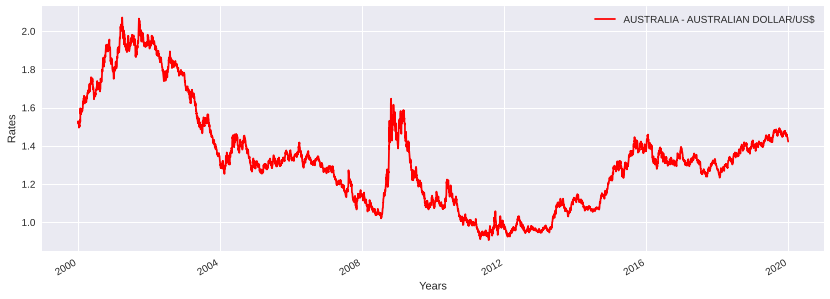

In [9]:
# plot the timeseries data with line plot

# list of colors which is cycled through no. of plots in this section
color=['red','green','blue', 'magenta'] 

# Plotting first column with plot width and height of 14 and 5 and color selected from the list 'color'
df.iloc[:, 0:1].plot(figsize=(14, 5), color=color[0])

# label of x-axis
plt.xlabel('Years') 
# label of y-axis
plt.ylabel('Rates') 

plt.show()

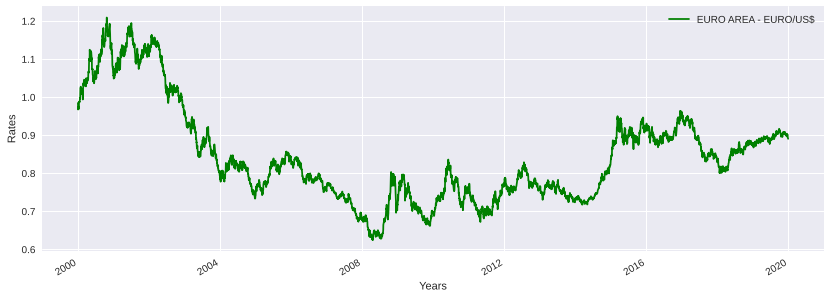

In [10]:
# plot the timeseries data with line plot
df.iloc[:, 1:2].plot(figsize=(14, 5), color=color[1])
plt.xlabel('Years')
plt.ylabel('Rates')
plt.show()

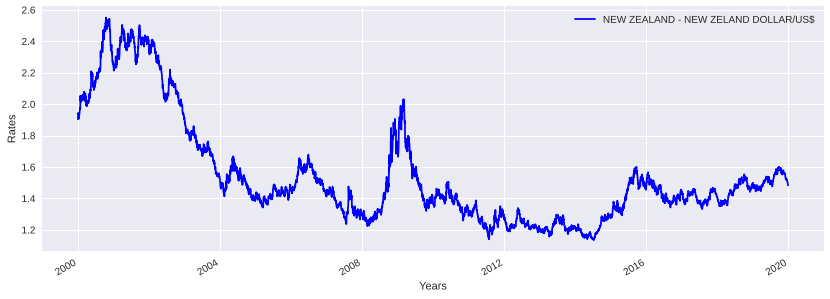

In [11]:
# plot the timeseries data with line plot
df.iloc[:, 2:3].plot(figsize=(14, 5), color=color[2])
plt.xlabel('Years')
plt.ylabel('Rates')
plt.show()

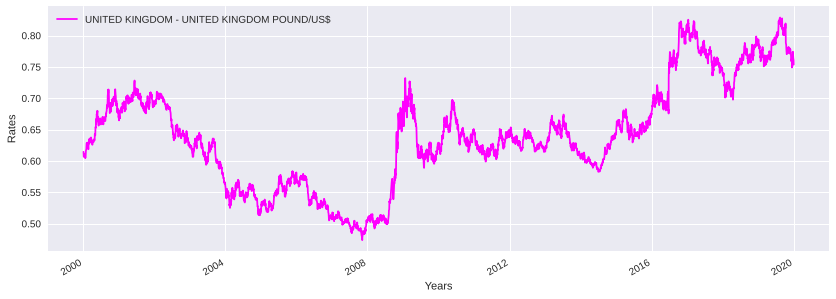

In [12]:
# plot the timeseries data with line plot
df.iloc[:, 3:4].plot(figsize=(14, 5), color=color[3])
plt.xlabel('Years')
plt.ylabel('Rates')
plt.show()

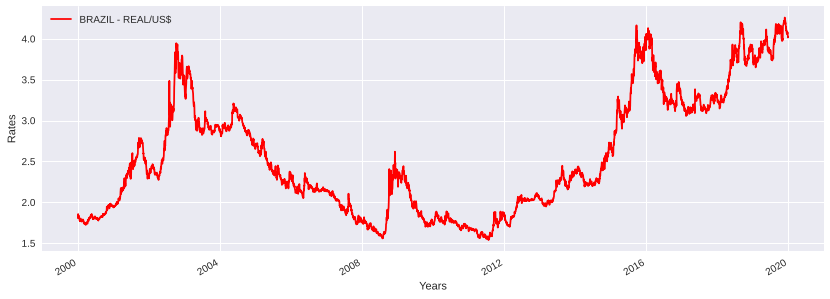

In [13]:
# plot the timeseries data with line plot
df.iloc[:, 4:5].plot(figsize=(14, 5), color=color[0])
plt.xlabel('Years')
plt.ylabel('Rates')
plt.show()

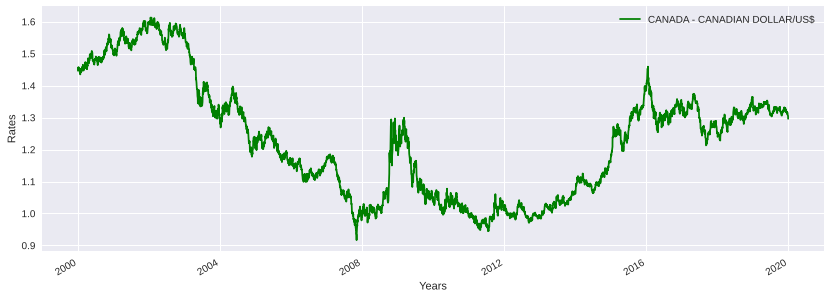

In [14]:
# plot the timeseries data with line plot
df.iloc[:, 5:6].plot(figsize=(14, 5), color=color[1])
plt.xlabel('Years')
plt.ylabel('Rates')
plt.show()

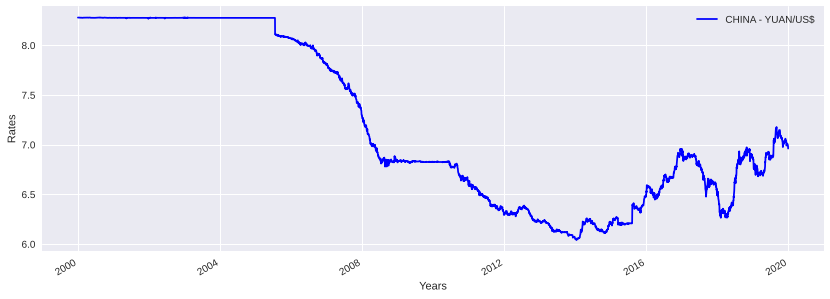

In [15]:
# plot the timeseries data with line plot
df.iloc[:, 6:7].plot(figsize=(14, 5), color=color[2])
plt.xlabel('Years')
plt.ylabel('Rates')
plt.show()

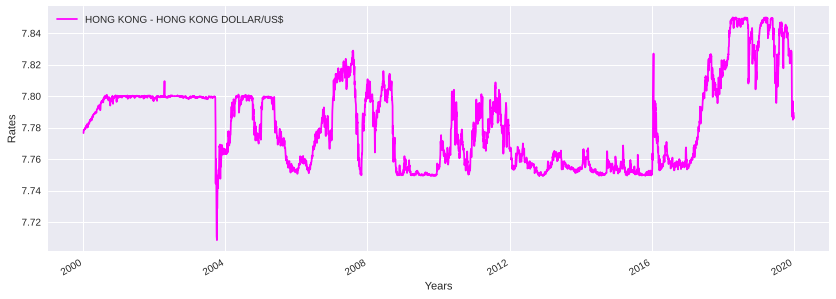

In [16]:
# plot the timeseries data with line plot
df.iloc[:, 7:8].plot(figsize=(14, 5), color=color[3])
plt.xlabel('Years')
plt.ylabel('Rates')
plt.show()

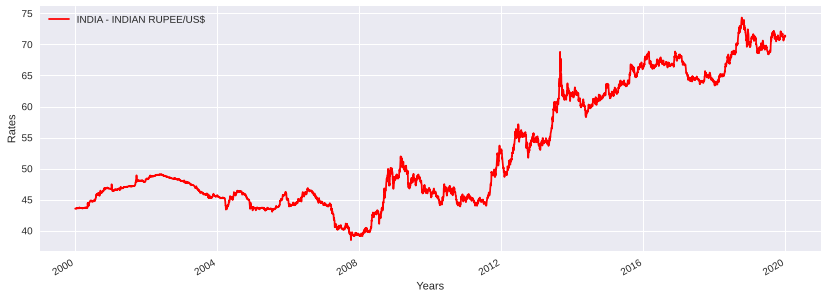

In [17]:
# plot the timeseries data with line plot
df.iloc[:, 8:9].plot(figsize=(14, 5), color=color[0])
plt.xlabel('Years')
plt.ylabel('Rates')
plt.show()

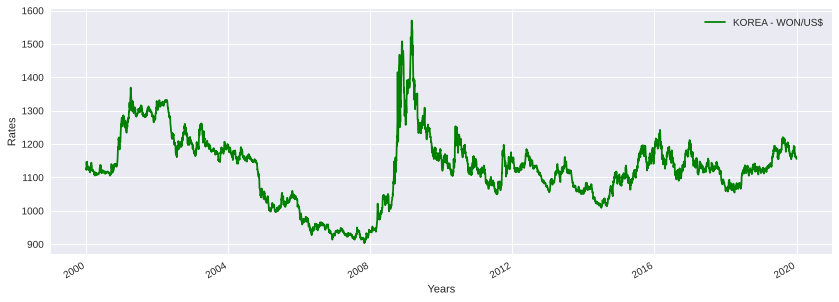

In [18]:
# plot the timeseries data with line plot
df.iloc[:, 9:10].plot(figsize=(14, 5), color=color[1])
plt.xlabel('Years')
plt.ylabel('Rates')
plt.show()

Text(0, 0.5, 'Rates')

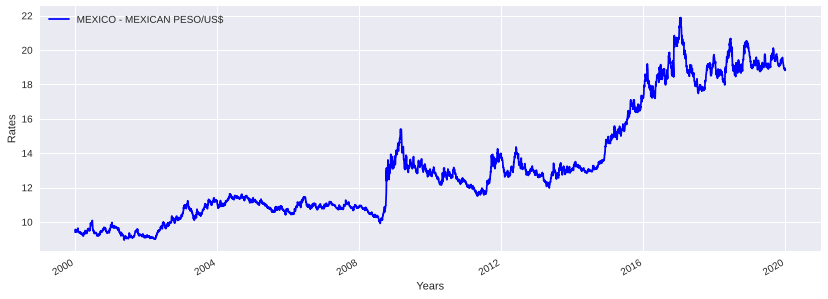

In [19]:
# plot the timeseries data with line plot
plot = df.iloc[:, 10:11].plot(figsize=(14, 5), color=color[2])
plot.set_xlabel('Years')
plot.set_ylabel('Rates')

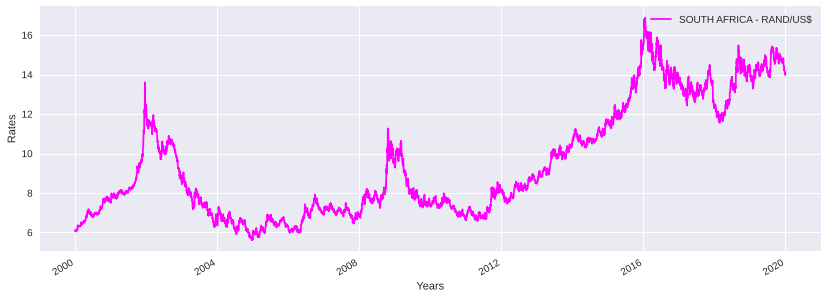

In [20]:
# plot the timeseries data with line plot
df.iloc[:, 11:12].plot(figsize=(14, 5), color=color[3])
plt.xlabel('Years')
plt.ylabel('Rates')
plt.show()

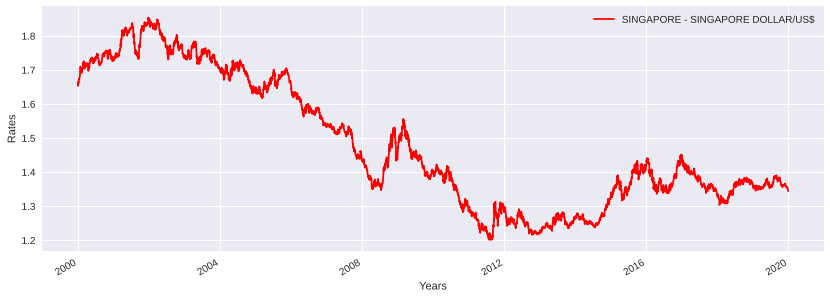

In [21]:
# plot the timeseries data with line plot
df.iloc[:, 12:13].plot(figsize=(14, 5), color=color[0])
plt.xlabel('Years')
plt.ylabel('Rates')
plt.show()

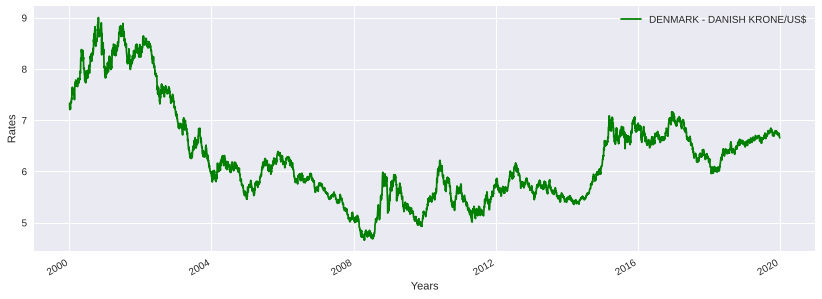

In [22]:
# plot the timeseries data with line plot
df.iloc[:, 13:14].plot(figsize=(14, 5), color=color[1])
plt.xlabel('Years')
plt.ylabel('Rates')
plt.show()

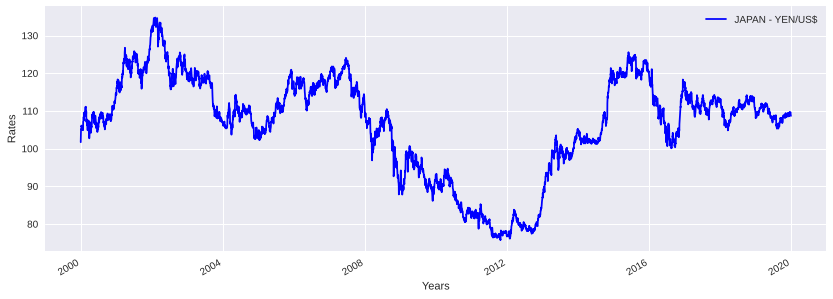

In [23]:
# plot the timeseries data with line plot
df.iloc[:, 14:15].plot(figsize=(14, 5), color=color[2])
plt.xlabel('Years')
plt.ylabel('Rates')
plt.show()

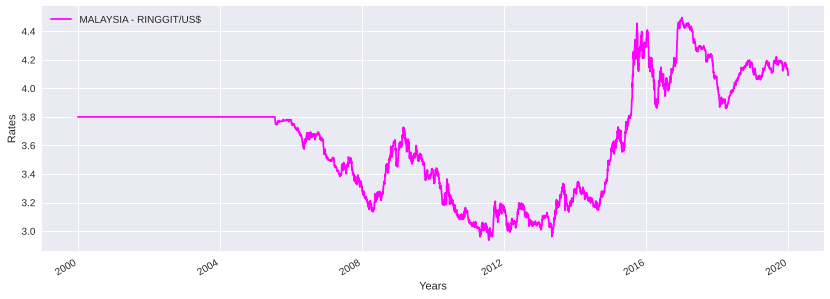

In [24]:
# plot the timeseries data with line plot
df.iloc[:, 15:16].plot(figsize=(14, 5), color=color[3])
plt.xlabel('Years')
plt.ylabel('Rates')
plt.show()

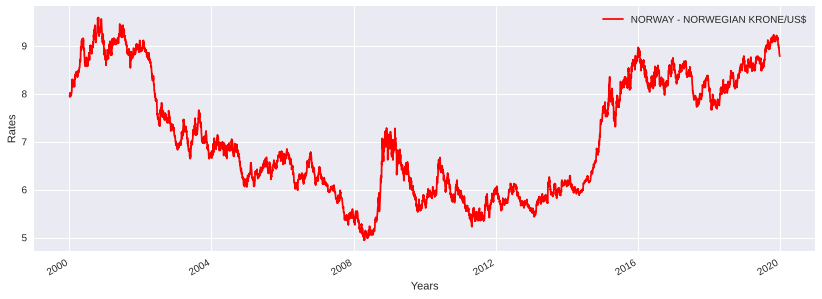

In [25]:
# plot the timeseries data with line plot
df.iloc[:, 16:17].plot(figsize=(14, 5), color=color[0])
plt.xlabel('Years')
plt.ylabel('Rates')
plt.show()

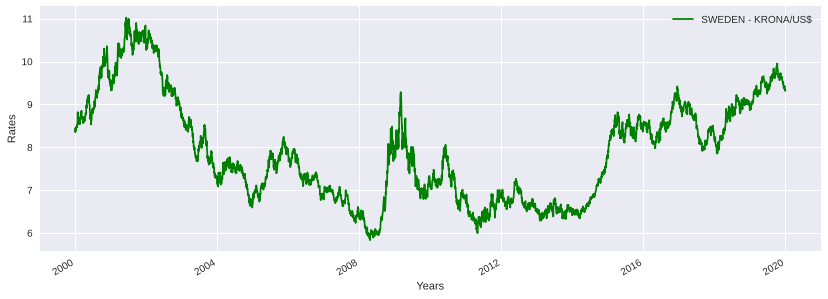

In [26]:
# plot the timeseries data with line plot
df.iloc[:, 17:18].plot(figsize=(14, 5), color=color[1])
plt.xlabel('Years')
plt.ylabel('Rates')
plt.show()

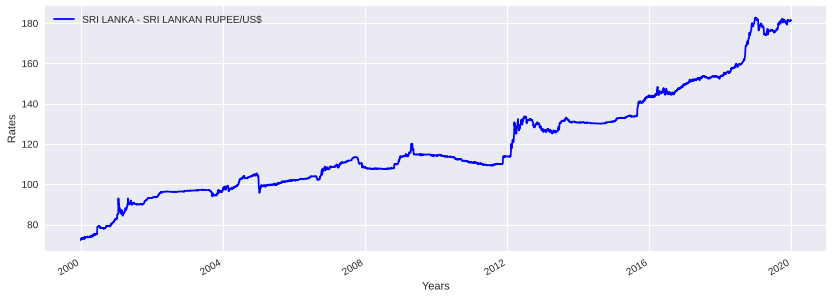

In [27]:
# plot the timeseries data with line plot
df.iloc[:, 18:19].plot(figsize=(14, 5), color=color[2])
plt.xlabel('Years')
plt.ylabel('Rates')
plt.show()

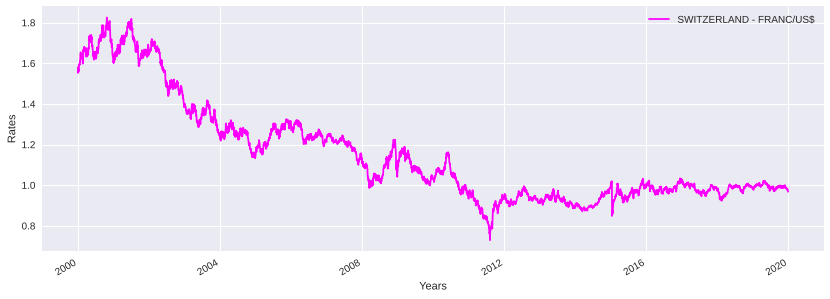

In [28]:
# plot the timeseries data with line plot
df.iloc[:, 19:20].plot(figsize=(14, 5), color=color[3])
plt.xlabel('Years')
plt.ylabel('Rates')
plt.show()

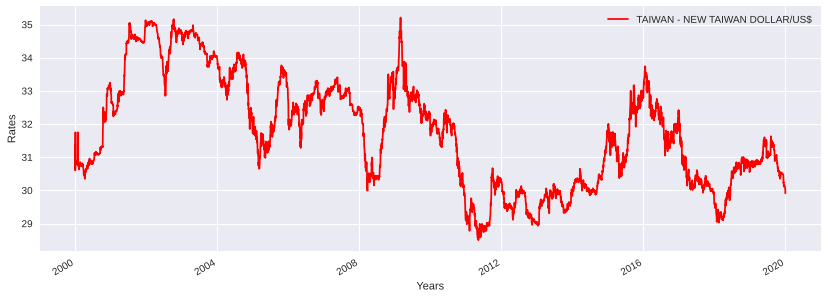

In [29]:
# plot the timeseries data with line plot
df.iloc[:, 20:21].plot(figsize=(14, 5), color=color[0])
plt.xlabel('Years')
plt.ylabel('Rates')
plt.show()

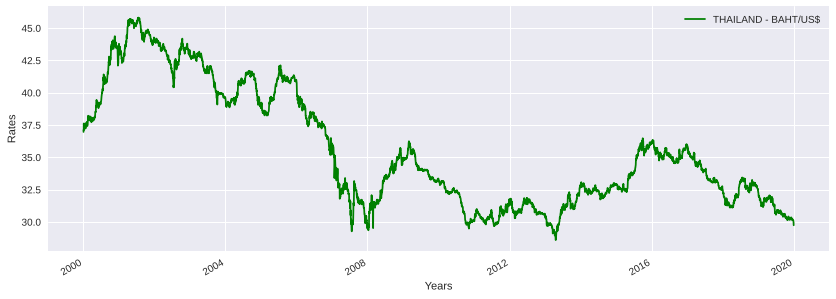

In [30]:
# plot the timeseries data with line plot
df.iloc[:, 21:22].plot(figsize=(14, 5), color=color[1])
plt.xlabel('Years')
plt.ylabel('Rates')
plt.show()

## Visualization of Timeseries Analysis of Single Year

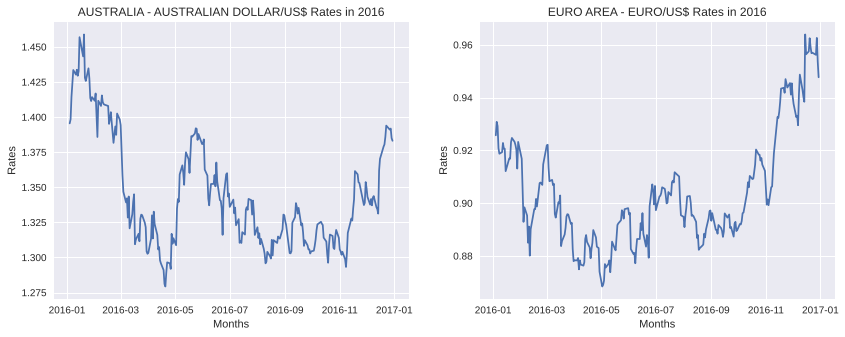

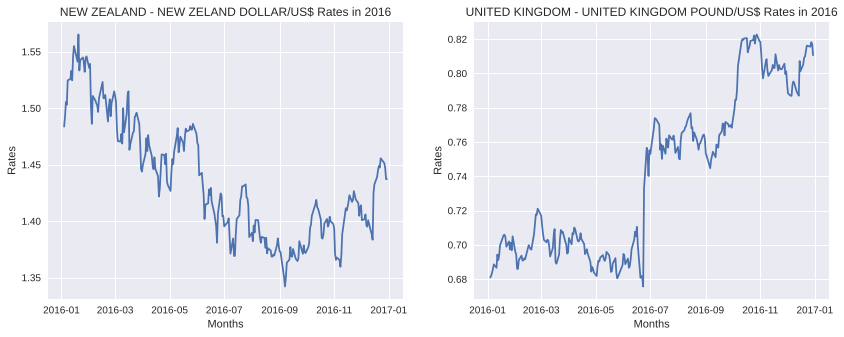

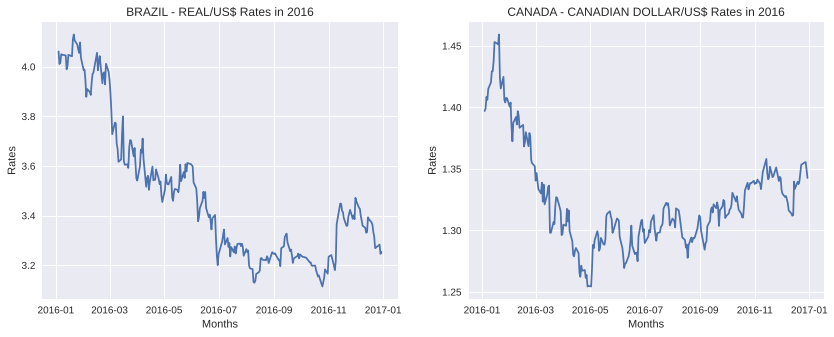

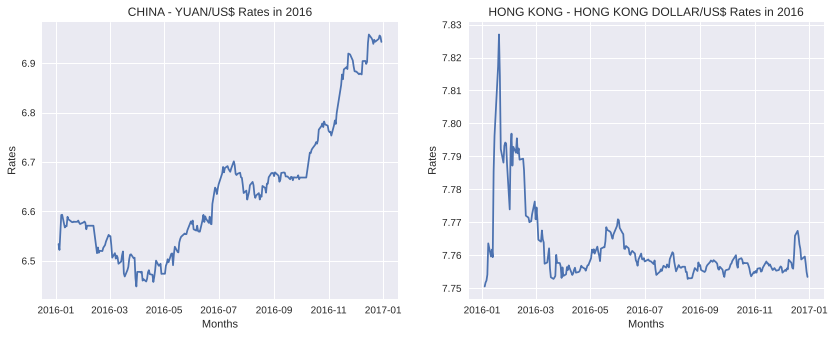

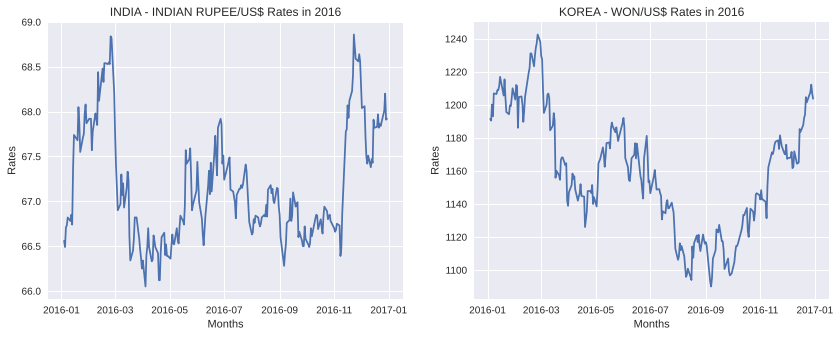

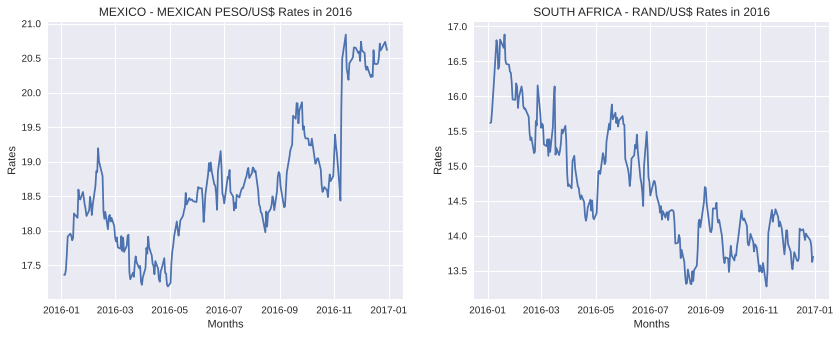

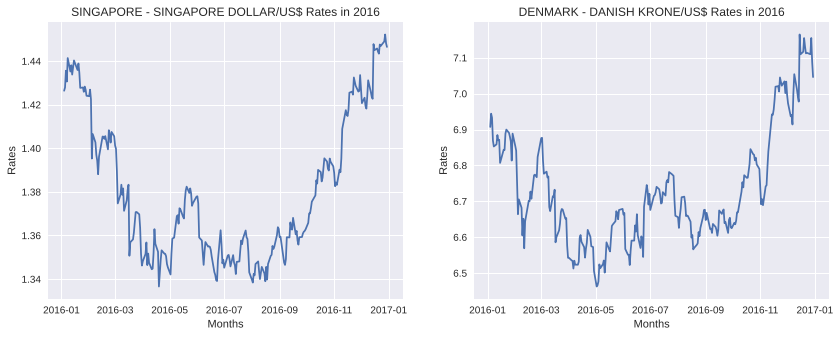

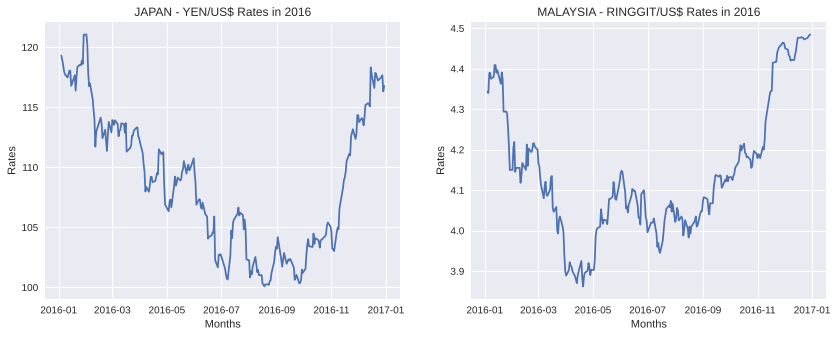

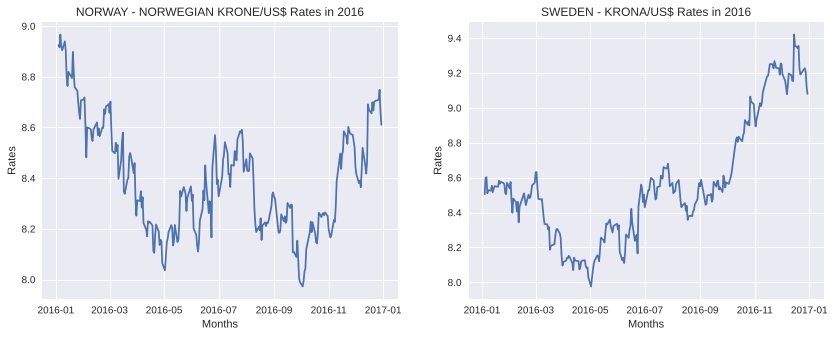

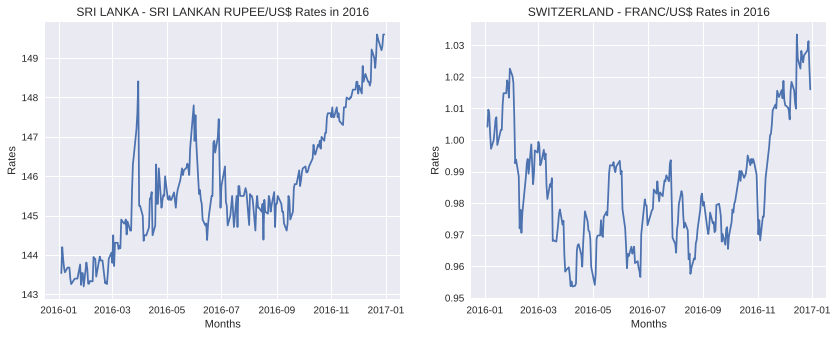

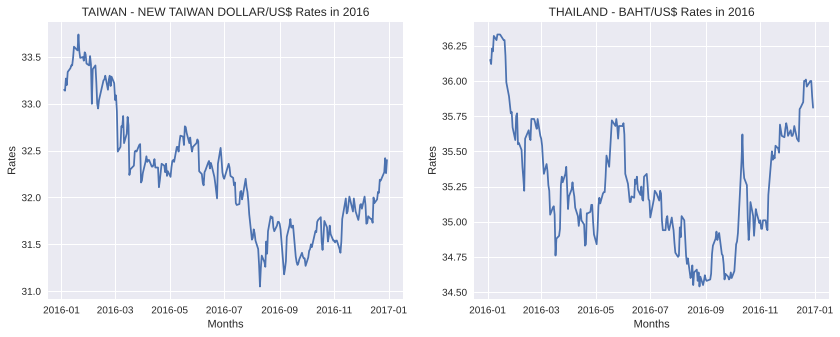

In [31]:
# plot the timeseries data with line plot

columns = df.columns

'''
This below for loop will loop through each 2 of columns of dataset and show subplots for both in single row separately 
(in 2 columns)

plt.subplot(1, 2, 1) - first parameter '1' is no. of rows we want in single figure or graph with subplots and 
                        second parameter '2' is no. of columns, finally third parameter '1' is subplot number

'''

for i in range(0, len(columns), 2):

    '''
    cols = columns[i:i+2] - In each iteration of for loop, this line will continously select 2 columns from list of columns 
    named 'columns' defined above in same cell (until the end of list) and create new dataframe with those 2 columns and 
    make it equal to 'data' variable which will later be used to define subplots containing those two columns
    '''
    
    cols = columns[i:i+2]
    data = df.loc['2016', cols]

    # setting the width and height of figure containing two subplots
    plt.figure(figsize=(14, 5))
    
    plt.subplot(1, 2, 1)
    plt.plot(data.iloc[:, 0])
    plt.xlabel('Months')
    plt.ylabel('Rates')
    plt.title(cols[0] + ' Rates in 2016')

    plt.subplot(1, 2, 2)
    plt.plot(data.iloc[:, 1])
    plt.title(cols[1] + ' Rates in 2016')
    plt.xlabel('Months')
    plt.ylabel('Rates')

    plt.show()

## Visualization of Timeseries Analysis of Dataset of Single Month

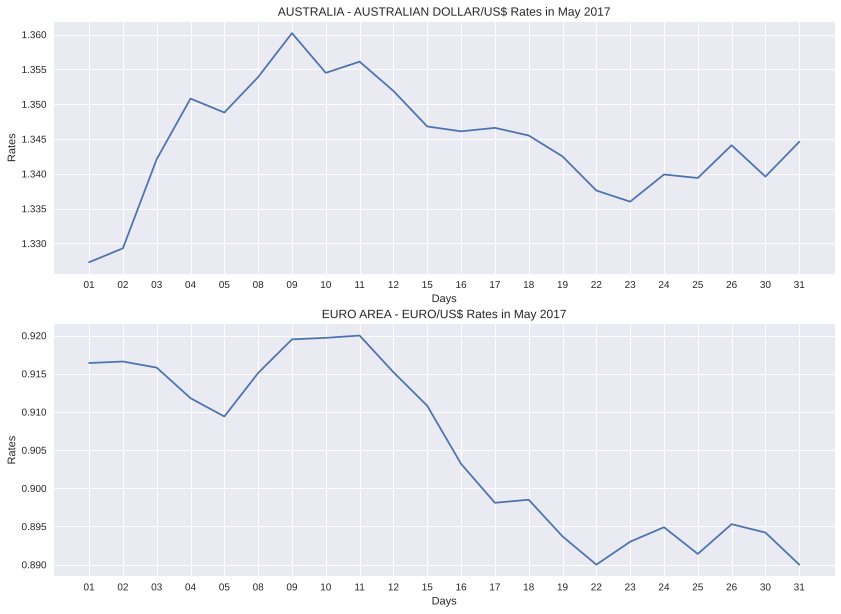

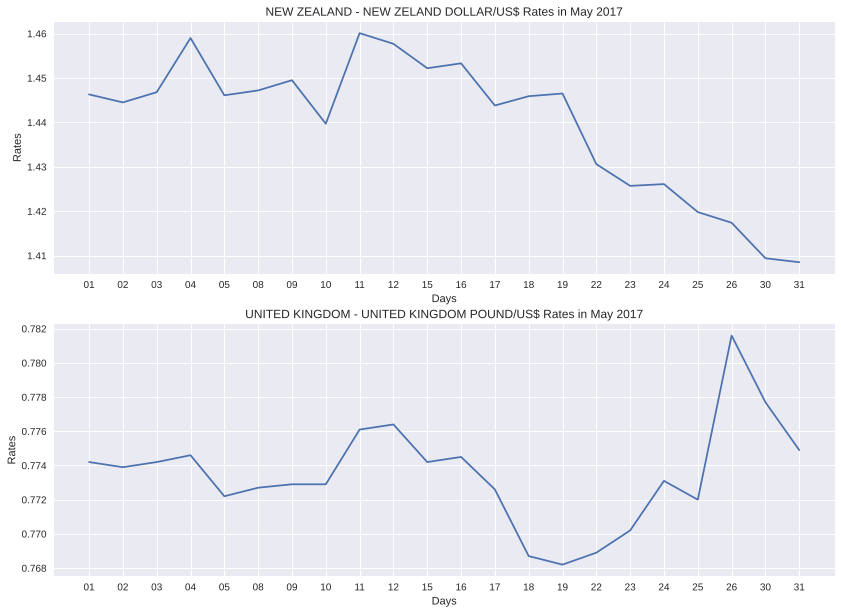

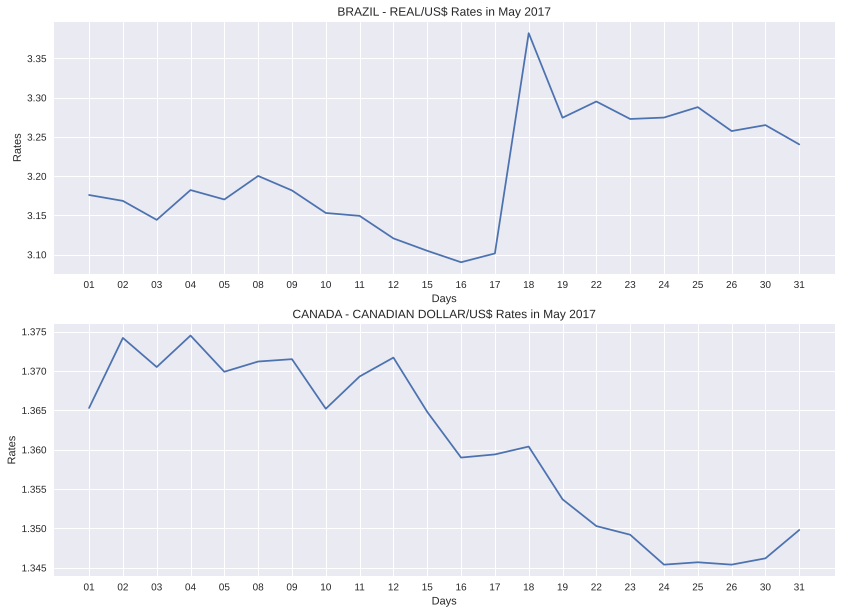

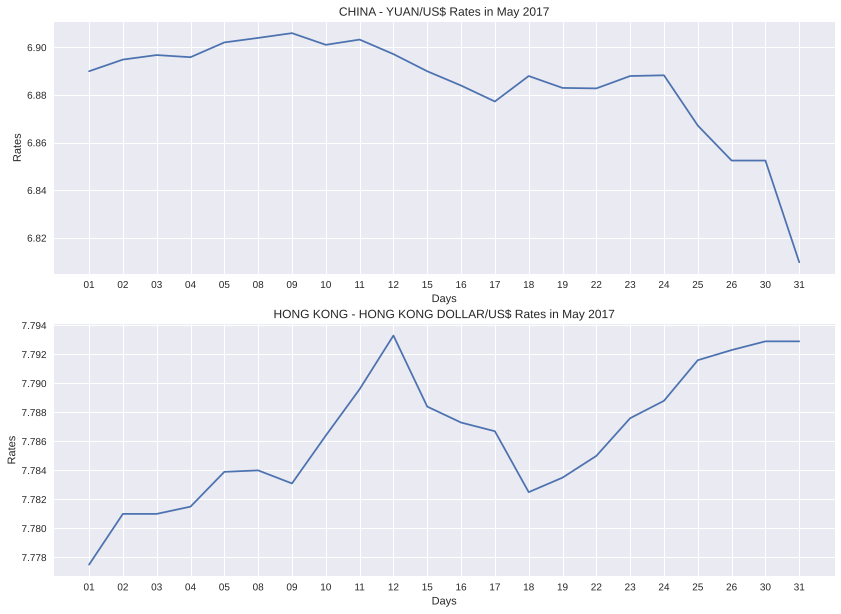

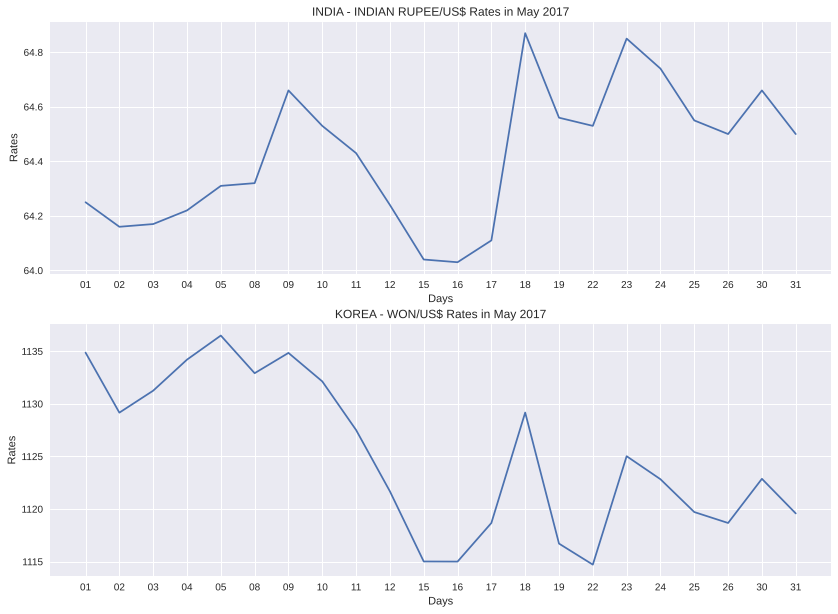

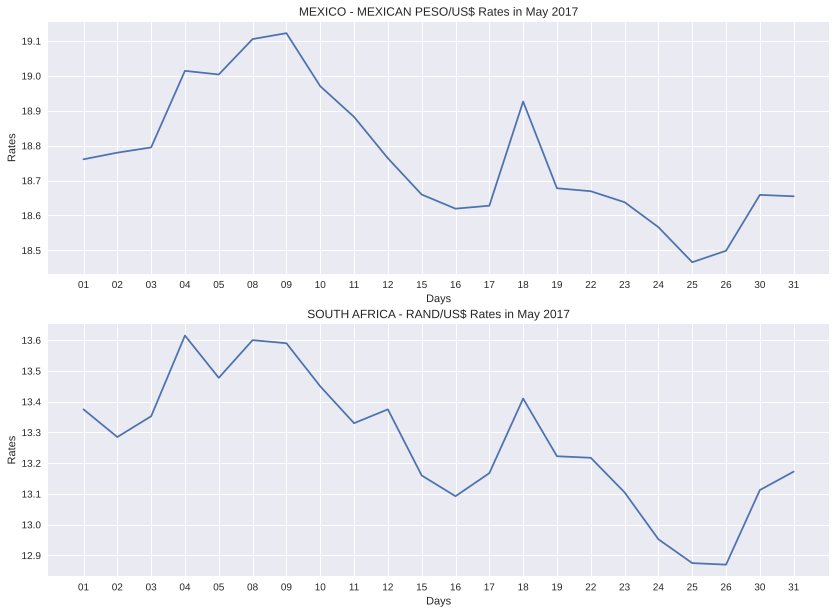

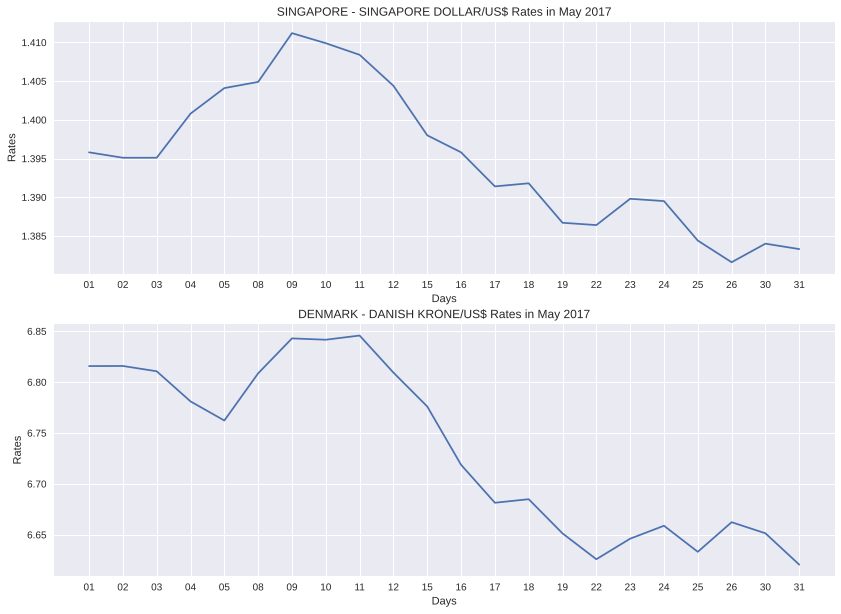

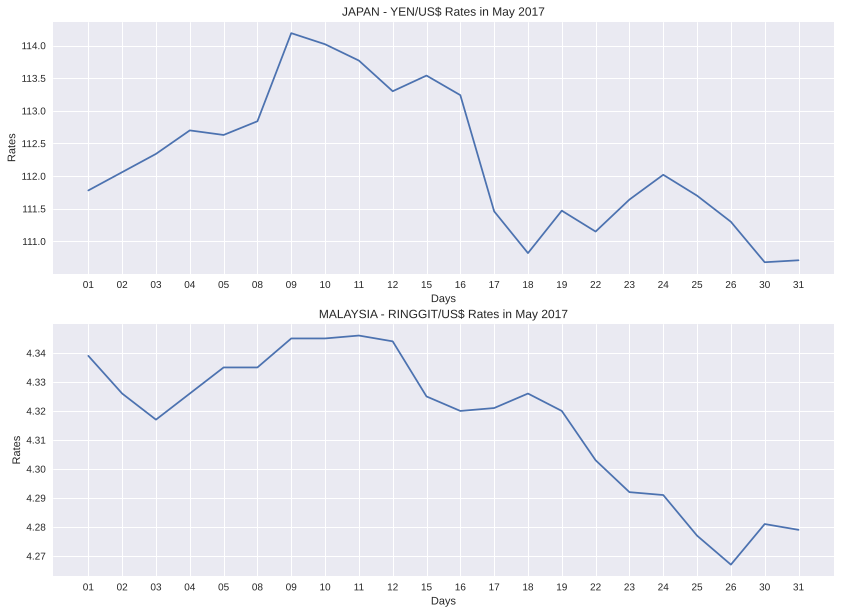

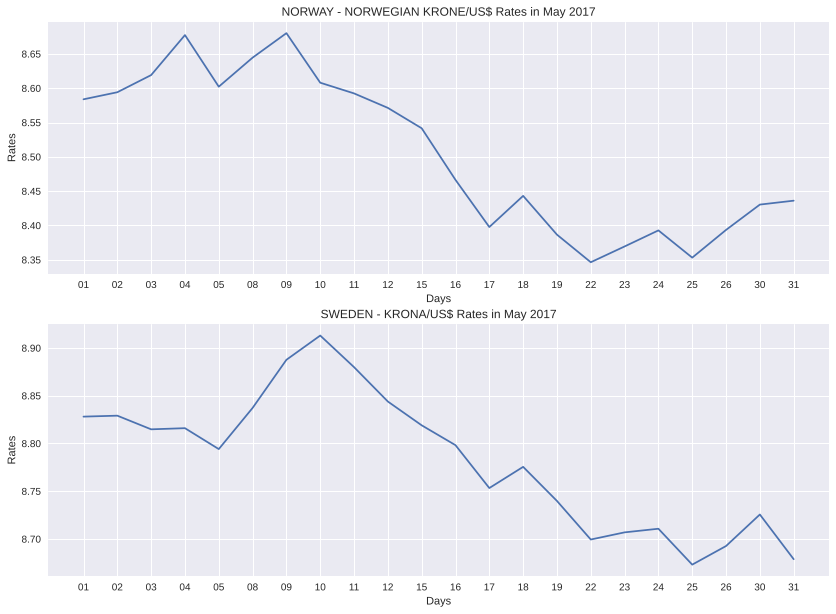

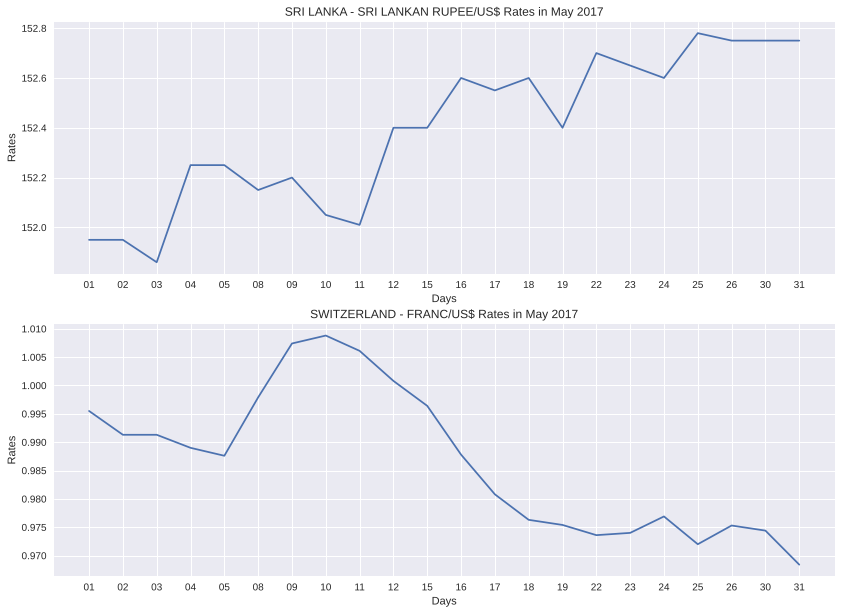

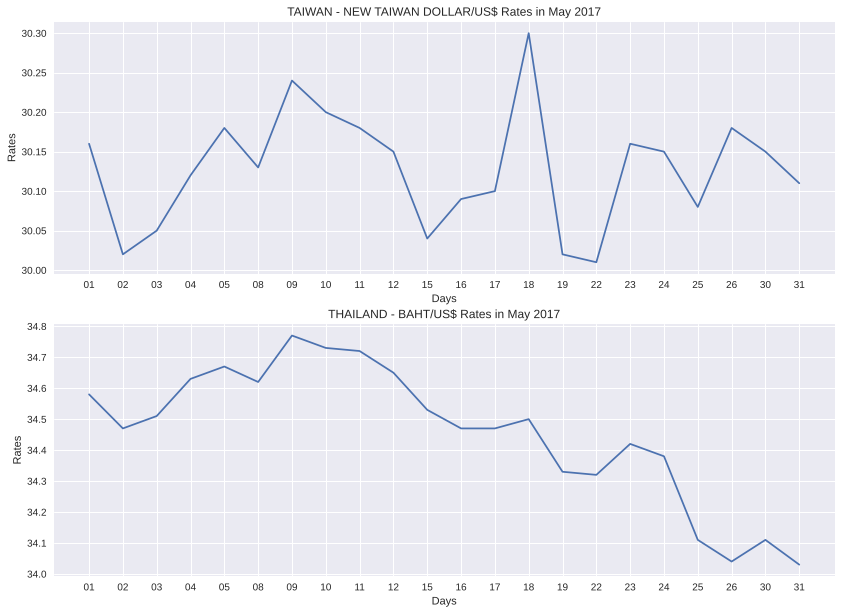

In [32]:
# plot the timeseries data with line plot

columns = df.columns

'''

plt.subplot(2, 1, 1) - Here instead of defining two subplots in single row with two columns, instead we're defining them 
                        in two rows with single column
                        
rest is following same pattern as defined in above cell

'''

for i in range(0, len(columns), 2):

    cols = columns[i:i+2]
    
    # Selecting Month of May in 2017
    data = df.loc['2017-05', cols]
    data.index = pd.to_datetime(data.index, format = '%m/%d/%Y').strftime('%d')    
    
    plt.figure(figsize=(14, 10))
    
    plt.subplot(2, 1, 1)
    plt.plot(data.iloc[:, 0])
    plt.xlabel('Days')
    plt.ylabel('Rates')
    plt.title(cols[0] + ' Rates in May 2017')

    plt.subplot(2, 1, 2)
    plt.plot(data.iloc[:, 1])
    plt.title(cols[1] + ' Rates in May 2017')
    plt.xlabel('Days')
    plt.ylabel('Rates')

    plt.show()

# APPLYING ARIMA MODEL (MACHINE LEARNING ALGORITHM) TO DATASET

## Exchange Rates Forecasting and Predictions Using Actual Data

In [33]:
'''

We are going to build ARIMA MODEL (MACHINE LEARNING Algorithm)  which is used mainly for analysing of timeseries data, 

specifically to forecast or predict future results of the data, e.g. forex exchange rates.

'''

# Set CURRENCY to a column name to run the notebook top-to-bottom without a prompt,
# or to None to choose interactively.
CURRENCY = 'UNITED KINGDOM - UNITED KINGDOM POUND/US$'

def select_currency():
    """Function that prompts user to select any curreny exchange rate column from the dataset to make predictions on it"""
    global df
    if CURRENCY is not None:
        return CURRENCY
    selected_currency = None
    keys = np.arange(1, len(df.columns) + 1)
    columns = df.columns.values
    options = dict(zip(keys, columns))

    print('List of Currencies:\n')
    for key, value in options.items():
        print('{}: {}'.format(key, value))

    try:
        while True:
            user_input = int(input('\nSelect Any Currency: '))

            if user_input not in options.keys():
                print('Wrong Input. Try Again')
                continue
            else:
                selected_currency = options[user_input]
                break
    except:
        print('Wrong Input. Try Again')
        
    return selected_currency

In [34]:
def Make_ARIMA_Prediction(actual, P, D, Q):
    """Function that uses ARIMA MODEL to make predictions or forecast given currency exchange rate column from dataset"""
    model = ARIMA(actual, order=(P, D, Q))
    model_fit = model.fit()
    return model_fit.forecast()[0]
    
    
selected_currency = select_currency()
print('\nSelected Currency: ', selected_currency, '\n')

ExchangeRates = df.loc[:, selected_currency]
ExchangeRates = ExchangeRates[~np.isnan(ExchangeRates.values)]
ExchangeRates.index = pd.DatetimeIndex(ExchangeRates.index).to_period('D')

actual_data = ExchangeRates.values
total_elements = len(actual_data)

# Using 70% from data as training and other 30% for testing the model
training_size = int(total_elements * 0.7)
training_data = actual_data[0:training_size]
test_data = actual_data[training_size:total_elements]

# New lists to save actual and predicted values
actual_values = [i for i in training_data]
predicted_values = []

# Predict values in for loop using ARIMA MODEL
for days in range(len(test_data)):
    actual_value =  test_data[days]
    #forecast value
    prediction = Make_ARIMA_Prediction(actual_values, 2,1,0)
    if days < 10:  # print the first few steps only; the full test set is ~1,500 days
        print('Actual={:.5f} \t Predicted={:.5f}'.format(actual_value, prediction))
    #adding values in the list
    predicted_values.append(prediction)
    actual_values.append(actual_value)

# Print MSE to check how accurate model was
mse_error = mean_squared_error(test_data, predicted_values)

'''
MSE or Mean Squared Error used in statistics to estimate average of squared errors between actual and estimated values, 
e.g. here predicted values generated by ARIMA MODEL. 

It is used in Machine Learning models like ARIMA, to check the quality of the model that how accurate that model has 
generated predictions.

If Mean Squared Error value is non-negative and closest to zero than it means the model has high correctness or it has 
better accuracy in generating predictions or future values based on any given trained data.
'''

# Below line will show Mean Squared Error value of ARIMA MODEL used on given dataset
# the more the smaller Mean Squared Error is, the more the model is accurate
print('\nMean Squared Error: {:.8f}'.format(mse_error))
print('RMSE: {:.6f}   MAE: {:.6f}'.format(np.sqrt(mse_error), mean_absolute_error(test_data, predicted_values)))

# Naive persistence baseline: tomorrow's rate = today's rate.
# Daily exchange rates are close to a random walk, so a forecasting model is only useful if it beats this.
naive_predictions = actual_data[training_size - 1:total_elements - 1]
naive_mse = mean_squared_error(test_data, naive_predictions)
print('\nPersistence baseline  MSE: {:.8f}   RMSE: {:.6f}'.format(naive_mse, np.sqrt(naive_mse)))
print('ARIMA(2,1,0) / persistence MSE ratio: {:.4f}'.format(mse_error / naive_mse))


"""https://towardsdatascience.com/forecasting-exchange-rates-using-arima-in-python-f032f313fc56"""



Selected Currency:  UNITED KINGDOM - UNITED KINGDOM POUND/US$ 

Actual=0.61140 	 Predicted=0.61141
Actual=0.61080 	 Predicted=0.61140
Actual=0.60880 	 Predicted=0.61079
Actual=0.60640 	 Predicted=0.60878


Actual=0.60530 	 Predicted=0.60638
Actual=0.60340 	 Predicted=0.60530
Actual=0.60820 	 Predicted=0.60339
Actual=0.60890 	 Predicted=0.60825


Actual=0.60930 	 Predicted=0.60889
Actual=0.60900 	 Predicted=0.60930



Mean Squared Error: 0.00001760
RMSE: 0.004196   MAE: 0.002917

Persistence baseline  MSE: 0.00001761   RMSE: 0.004196
ARIMA(2,1,0) / persistence MSE ratio: 0.9997


'https://towardsdatascience.com/forecasting-exchange-rates-using-arima-in-python-f032f313fc56'

### Note on evaluation

Forecasts are made one step ahead with walk-forward refitting: after each test day the true value is appended to the history and the model is refitted. Because daily exchange rates behave much like a random walk, the cell above also reports a persistence baseline (predict today's rate for tomorrow). An MSE ratio close to 1 means ARIMA(2,1,0) adds little beyond that baseline; this is the expected result for liquid currency pairs and is the honest reading of the plot below, where the prediction line closely shadows the actual series with a one-day lag.


## Visualization of Actual vs Prediction values generated by ARIMA MODEL

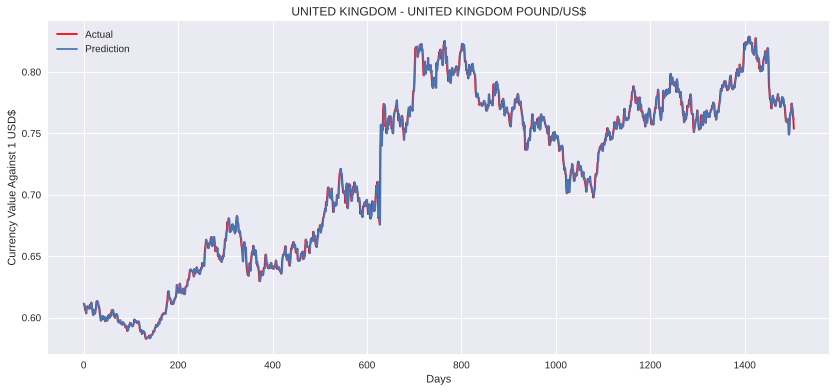

In [35]:
# plotting the graph of actual vs prediction

'''
red line (which shows actual values) will be there in graph, you will see the glimpse of it. This will reflect the 
correctness of model in case of red line not being shown clearly in graph which means it's going nearest with green line.
'''

plt.figure(figsize=(14, 6))
plt.plot(test_data, color='red', label='Actual')
plt.plot(predicted_values, label='Prediction')
plt.title(selected_currency)
plt.xlabel('Days')
plt.ylabel('Currency Value Against 1 USD$')
plt.legend(loc='upper left')

plt.show()


# AIMS COMPLETED

## Completed all aims set at the start of this notebook.

1. Successfully performed Timeseries Analysis on Forex Exchange Dataset, covering all historical aspects of it

2. Cleaned and Transformed the Forex Exchange Rate dataset successfully in a way that we were able to effectively perform Timeseries Analysis on it and also applied ARIMA MODEL (Machine Learning Algorithm), as both required cleaned, numerical, data without missing values.

3. Perfomed visualization of Timeseries Analysis done on Forex exchange dataset, which includes Yearly, Monthly, and Day-wise plotting of each currency exchange rate in the dataset.

4. Successfully build ARIMA MODEL (Machine Learning Algorithm) and applied it on forex exchange data by using 70% of existing data to train the model and tested on remaining 30%. As a result, we can now make use of this model to predict future values of each currency exchange rate.